# Customer Churn Prediction - Complete Analysis


## Project Overview

This notebook predicts whether a telecom customer is likely to churn.
The analysis follows a leakage-safe machine-learning workflow:

1. Verify and understand the original data.
2. Audit quality and target relationships.
3. Perform exploratory data analysis.
4. Preserve a fully untouched test set.
5. Compare eleven machine-learning models.
6. Use out-of-fold predictions to select a probability threshold.
7. Refit the selected pipeline on the full training split.
8. Evaluate the selected pipeline once on the untouched test set.

The notebook deliberately distinguishes cross-validation, validation, out-of-fold threshold selection and final test metrics.


## 1. Dataset and Business Objective


The verified Kaggle Customer Churn Dataset contains customer demographics and account information.
The machine-learning objective is binary classification:

- `0` means the customer is likely to stay.
- `1` means the customer is likely to churn.

`CustomerID` is an identifier, not a behavioral predictor, and is excluded from every model.


## 2. Import Libraries

In [1]:
from pathlib import Path
import json
import subprocess
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    classification_report,
)

sns.set_theme(style="whitegrid")


## 3. Define Portable Project Paths

In [2]:
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATASET_PATH = ROOT / "dataset" / "customer_churn.csv"
MODEL_PATH = ROOT / "models" / "churn_model.pkl"
METRICS_PATH = ROOT / "model_metrics.json"
COMPARISON_PATH = ROOT / "model_comparison.csv"

print("Project root:", ROOT)
print("Dataset:", DATASET_PATH)


Project root: C:\Users\dell\Downloads\Customer-Churn-Prediction-Advanced
Dataset: C:\Users\dell\Downloads\Customer-Churn-Prediction-Advanced\dataset\customer_churn.csv


## 4. Load the Original Dataset

In [3]:
df = pd.read_csv(DATASET_PATH)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (64374, 12)


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0


## 5. Inspect the Last Records

In [4]:
display(df.tail())


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
64369,64370,45,Female,33,12,6,21,Basic,Quarterly,947,14,1
64370,64371,37,Male,6,1,5,22,Standard,Annual,923,9,1
64371,64372,25,Male,39,14,8,30,Premium,Monthly,327,20,1
64372,64373,50,Female,18,19,7,22,Standard,Monthly,540,13,1
64373,64374,52,Female,45,15,9,25,Standard,Monthly,696,22,1


## 6. Verify Dataset Dimensions

In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


Rows: 64374
Columns: 12


## 7. Dataset Schema

In [6]:
display(pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notna().sum().values,
}).set_index("Column"))


,Data Type,Non-Null Count
Column,,
CustomerID,int64,64374
Age,int64,64374
Gender,object,64374
Tenure,int64,64374
Usage Frequency,int64,64374
Support Calls,int64,64374
Payment Delay,int64,64374
Subscription Type,object,64374
Contract Length,object,64374


## 8. DataFrame Information

In [7]:
display(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64374 entries, 0 to 64373
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   CustomerID         64374 non-null  int64 
 1   Age                64374 non-null  int64 
 2   Gender             64374 non-null  object
 3   Tenure             64374 non-null  int64 
 4   Usage Frequency    64374 non-null  int64 
 5   Support Calls      64374 non-null  int64 
 6   Payment Delay      64374 non-null  int64 
 7   Subscription Type  64374 non-null  object
 8   Contract Length    64374 non-null  object
 9   Total Spend        64374 non-null  int64 
 10  Last Interaction   64374 non-null  int64 
 11  Churn              64374 non-null  int64 
dtypes: int64(9), object(3)
memory usage: 5.9+ MB


None

## 9. Statistical Summary

In [8]:
display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,64374.0,NaN,NaN,NaN,32187.5,18583.317451,1.0,16094.25,32187.5,48280.75,64374.0
Age,64374.0,NaN,NaN,NaN,41.970982,13.924911,18.0,30.0,42.0,54.0,65.0
Gender,64374,2,Female,34353,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tenure,64374.0,NaN,NaN,NaN,31.994827,17.098234,1.0,18.0,33.0,47.0,60.0
Usage Frequency,64374.0,NaN,NaN,NaN,15.080234,8.81647,1.0,7.0,15.0,23.0,30.0
Support Calls,64374.0,NaN,NaN,NaN,5.40069,3.114005,0.0,3.0,6.0,8.0,10.0
Payment Delay,64374.0,NaN,NaN,NaN,17.133952,8.852211,0.0,10.0,19.0,25.0,30.0
Subscription Type,64374,3,Standard,21502,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Contract Length,64374,3,Monthly,22130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Spend,64374.0,NaN,NaN,NaN,541.023379,260.874809,100.0,313.0,534.0,768.0,1000.0


## 10. Identify Numerical and Categorical Features

In [9]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

numerical_columns = [c for c in numerical_columns if c not in ("Churn", "CustomerID")]
categorical_columns = [c for c in categorical_columns if c != "CustomerID"]

print("Numerical features:", numerical_columns)
print("Categorical features:", categorical_columns)


Numerical features: ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']
Categorical features: ['Gender', 'Subscription Type', 'Contract Length']


## 11. Target and Identifier

In [10]:
print("Target:", "Churn")
print("Identifier:", "CustomerID")
print("Target values:", df["Churn"].value_counts(dropna=False).to_dict())


Target: Churn
Identifier: CustomerID
Target values: {0: 33881, 1: 30493}


## 12. Missing Values

In [11]:
missing = df.isna().sum().sort_values(ascending=False)
missing_percent = (df.isna().mean() * 100).sort_values(ascending=False)
display(pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percent,
}))


,Missing Count,Missing Percentage
CustomerID,0,0.0
Age,0,0.0
Gender,0,0.0
Tenure,0,0.0
Usage Frequency,0,0.0
Support Calls,0,0.0
Payment Delay,0,0.0
Subscription Type,0,0.0
Contract Length,0,0.0
Total Spend,0,0.0


## 13. Missing-Value Visualization

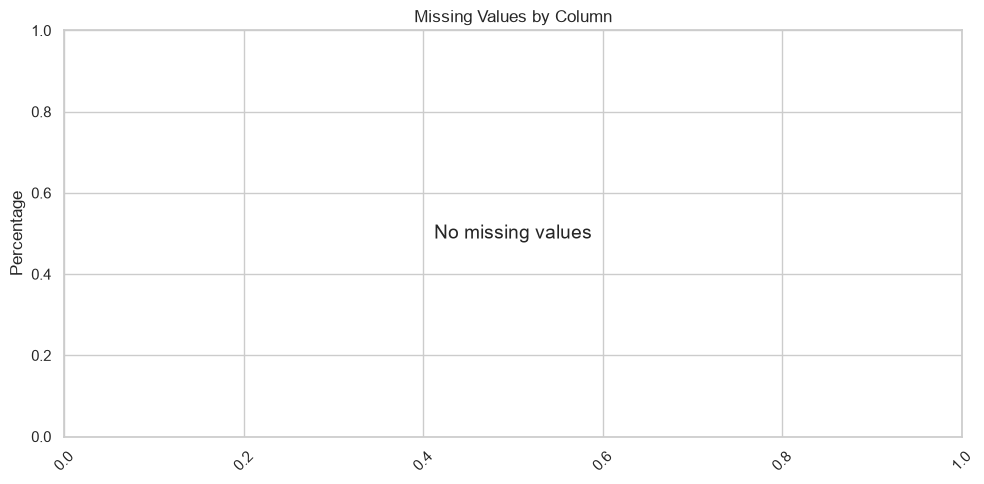

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
missing_with_values = missing_percent[missing_percent > 0]
if missing_with_values.empty:
    ax.text(
        0.5,
        0.5,
        "No missing values",
        ha="center",
        va="center",
        transform=ax.transAxes,
        fontsize=14,
    )
else:
    missing_with_values.plot(kind="bar", ax=ax, color="#64748b")
ax.set_title("Missing Values by Column")
ax.set_ylabel("Percentage")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


If no columns appear in the chart, the dataset has no missing values.

## 14. Duplicate Rows

In [13]:
print("Exact duplicate rows:", df.duplicated().sum())


Exact duplicate rows: 0


## 15. Duplicate Customer IDs

In [14]:
print("Duplicate CustomerID values:", df["CustomerID"].duplicated().sum())
print("Unique CustomerID values:", df["CustomerID"].nunique())


Duplicate CustomerID values: 0
Unique CustomerID values: 64374


## 16. Constant and Low-Cardinality Columns

In [15]:
cardinality = df.nunique(dropna=True).sort_values()
display(cardinality.to_frame("Unique Values"))
print("Constant columns:", df.columns[df.nunique(dropna=False) <= 1].tolist())


,Unique Values
Gender,2
Churn,2
Subscription Type,3
Contract Length,3
Support Calls,11
Usage Frequency,30
Last Interaction,30
Payment Delay,31
Age,48
Tenure,60


Constant columns: []


## 17. Target Distribution

,Count
Churn,
0,33881
1,30493


,Proportion
Churn,
0,0.526315
1,0.473685


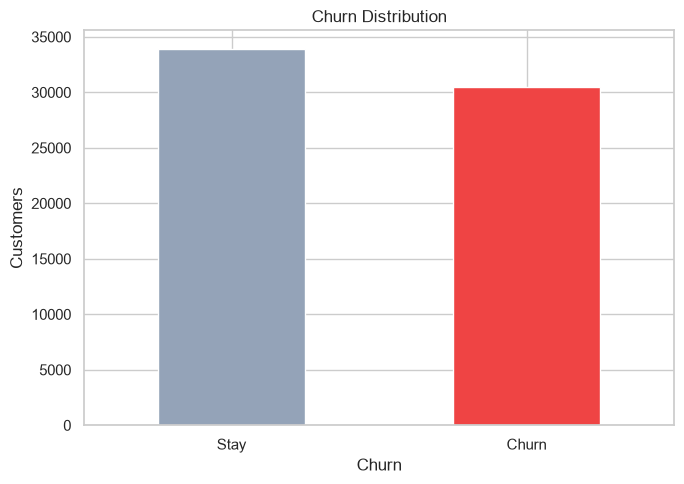

In [16]:
target_counts = df["Churn"].value_counts().sort_index()
display(target_counts.to_frame("Count"))
display((target_counts / len(df)).to_frame("Proportion"))

fig, ax = plt.subplots(figsize=(7, 5))
target_counts.plot(kind="bar", ax=ax, color=["#94a3b8", "#ef4444"])
ax.set_xticklabels(["Stay", "Churn"], rotation=0)
ax.set_title("Churn Distribution")
ax.set_ylabel("Customers")
plt.tight_layout()
plt.show()


## 18. Target Balance Interpretation

A balanced or moderately imbalanced target determines whether accuracy alone is sufficient. This project reports precision, recall, F1 and ROC-AUC in addition to accuracy.

## 19. Age Distribution

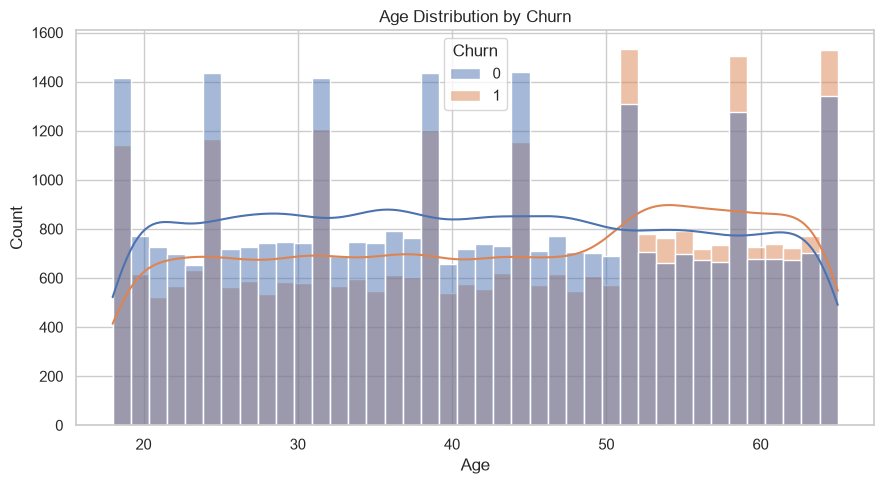

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=df, x="Age", hue="Churn", bins=40, kde=True, ax=ax)
ax.set_title("Age Distribution by Churn")
plt.tight_layout()
plt.show()


## 20. Age Boxplot

C:\Users\dell\AppData\Local\Temp\ipykernel_26568\3255022780.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Stay", "Churn"])


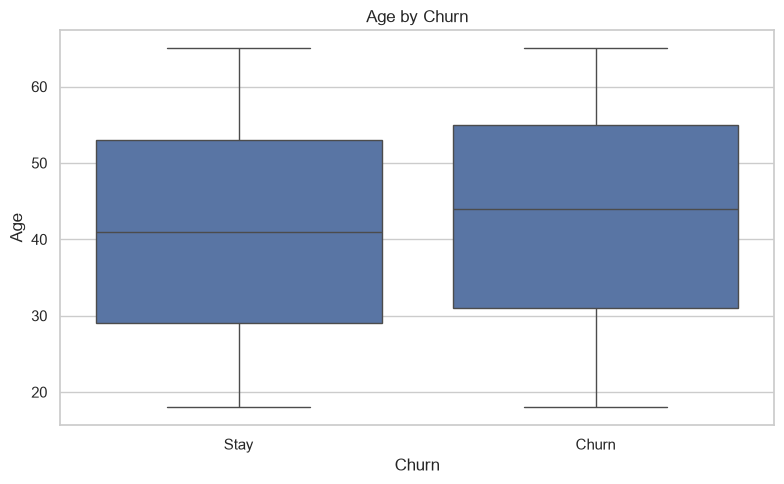

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="Age", ax=ax)
ax.set_xticklabels(["Stay", "Churn"])
ax.set_title("Age by Churn")
plt.tight_layout()
plt.show()


## 21. Tenure Distribution

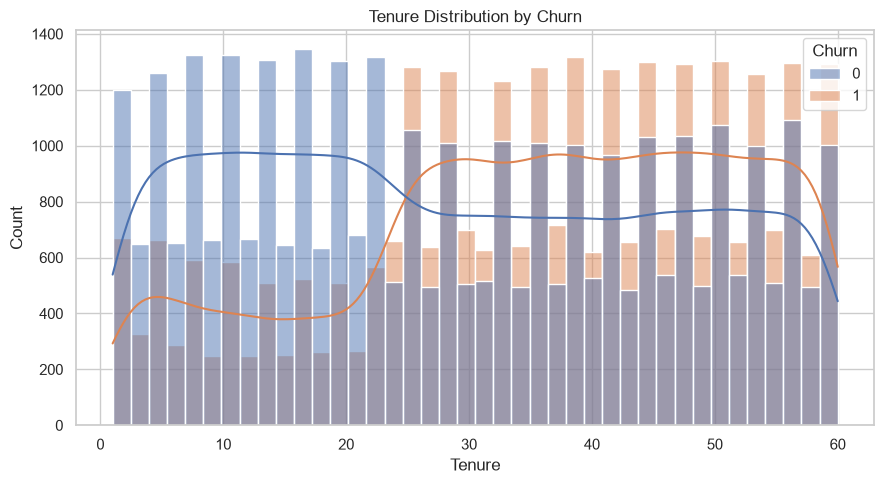

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=df, x="Tenure", hue="Churn", bins=40, kde=True, ax=ax)
ax.set_title("Tenure Distribution by Churn")
plt.tight_layout()
plt.show()


## 22. Tenure vs Churn

C:\Users\dell\AppData\Local\Temp\ipykernel_26568\3883240702.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Stay", "Churn"])


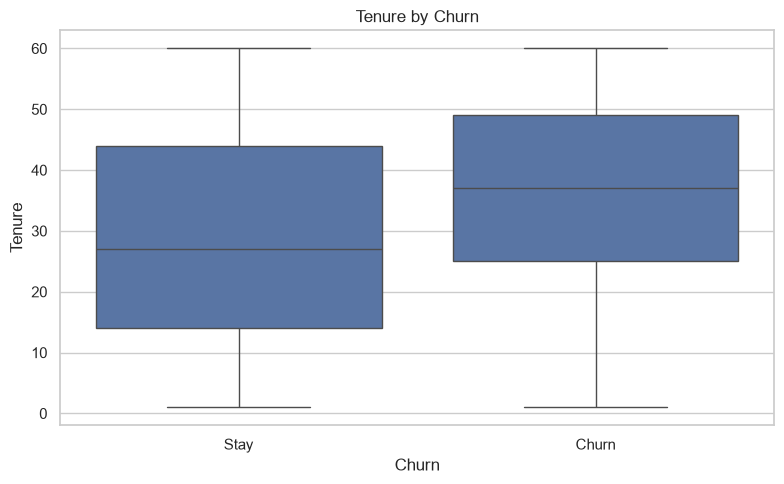

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="Tenure", ax=ax)
ax.set_xticklabels(["Stay", "Churn"])
ax.set_title("Tenure by Churn")
plt.tight_layout()
plt.show()


## 23. Usage Frequency Distribution

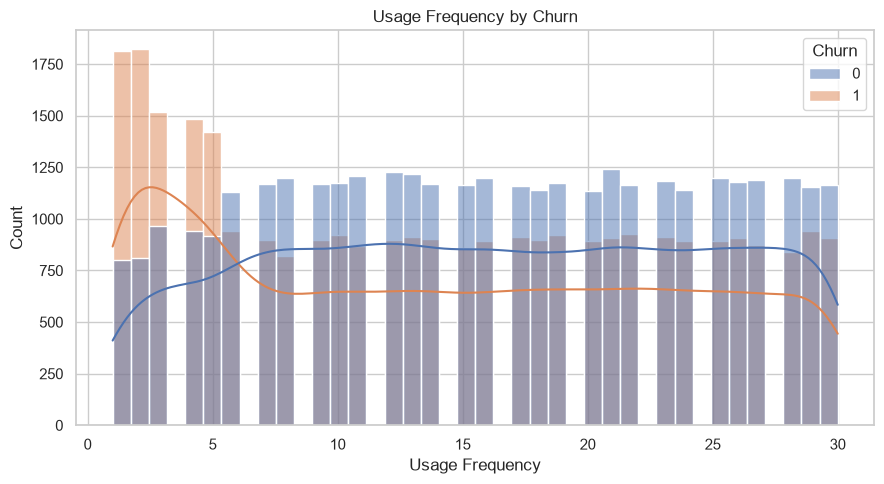

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=df, x="Usage Frequency", hue="Churn", bins=40, kde=True, ax=ax)
ax.set_title("Usage Frequency by Churn")
plt.tight_layout()
plt.show()


## 24. Support Calls Distribution

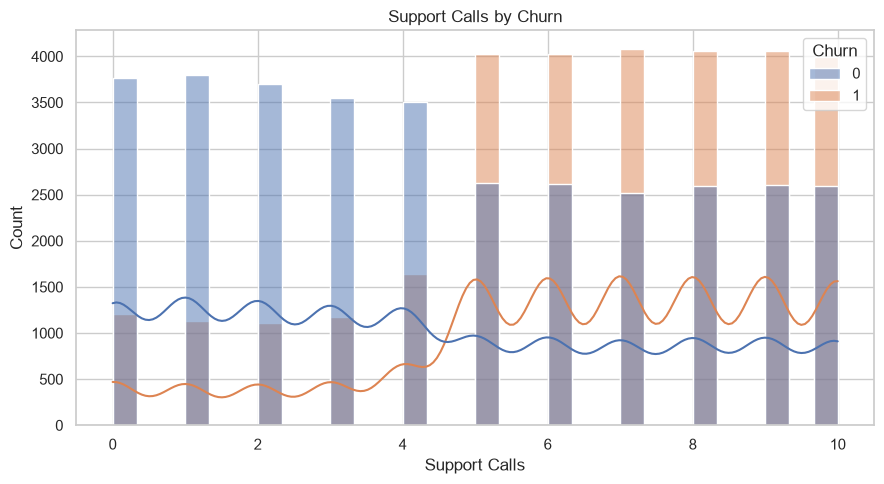

In [22]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=df, x="Support Calls", hue="Churn", bins=30, kde=True, ax=ax)
ax.set_title("Support Calls by Churn")
plt.tight_layout()
plt.show()


## 25. Payment Delay Distribution

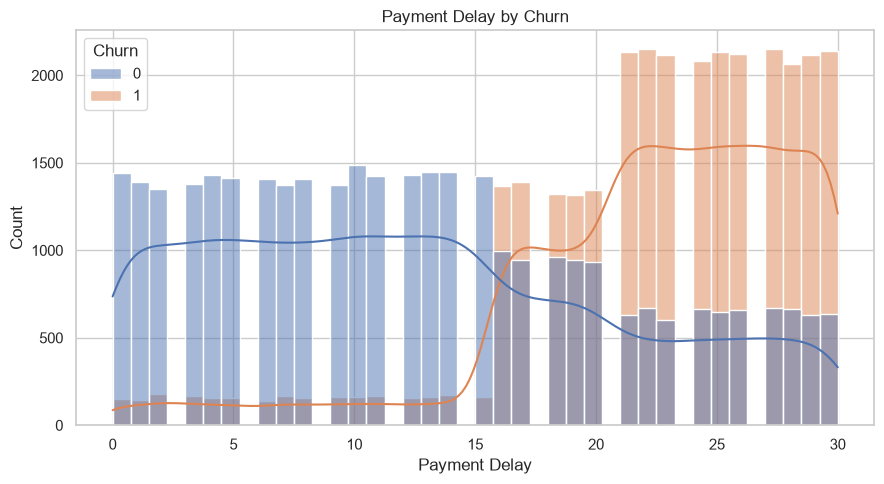

In [23]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=df, x="Payment Delay", hue="Churn", bins=40, kde=True, ax=ax)
ax.set_title("Payment Delay by Churn")
plt.tight_layout()
plt.show()


## 26. Total Spend Distribution

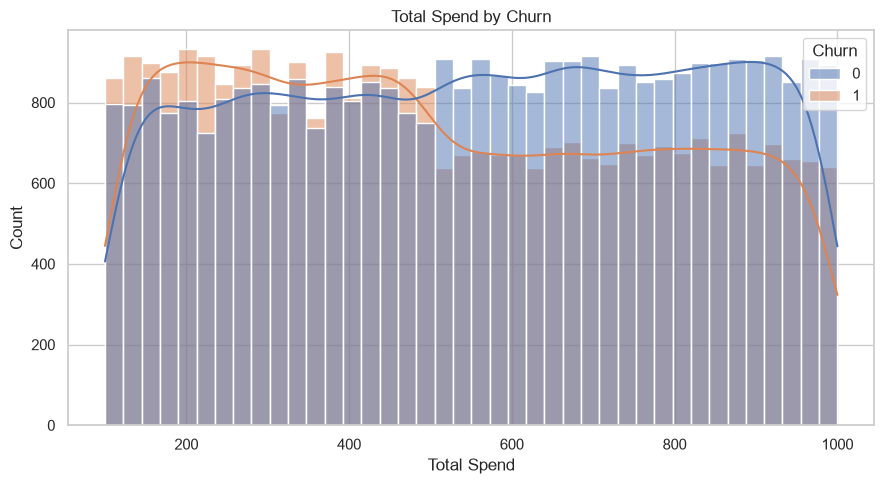

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=df, x="Total Spend", hue="Churn", bins=40, kde=True, ax=ax)
ax.set_title("Total Spend by Churn")
plt.tight_layout()
plt.show()


## 27. Last Interaction Distribution

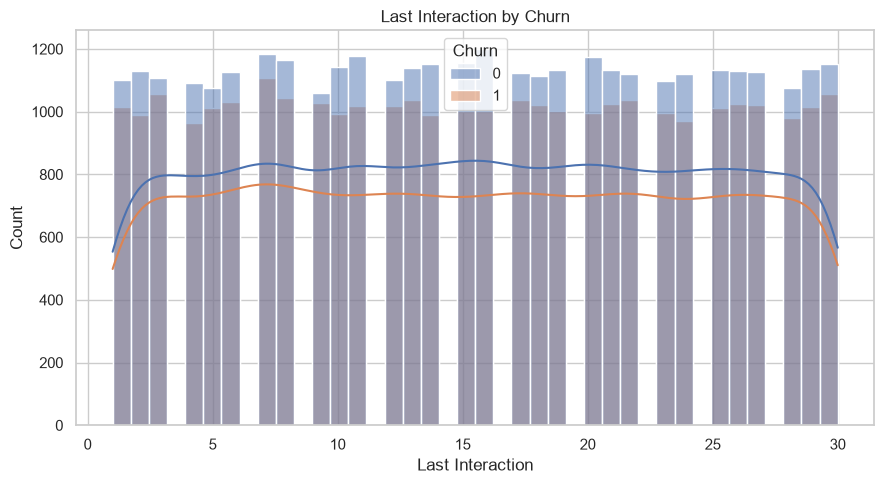

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=df, x="Last Interaction", hue="Churn", bins=40, kde=True, ax=ax)
ax.set_title("Last Interaction by Churn")
plt.tight_layout()
plt.show()


## 28. Gender vs Churn

Churn,0,1
Gender,,
Female,0.449510,0.550490
Male,0.614203,0.385797


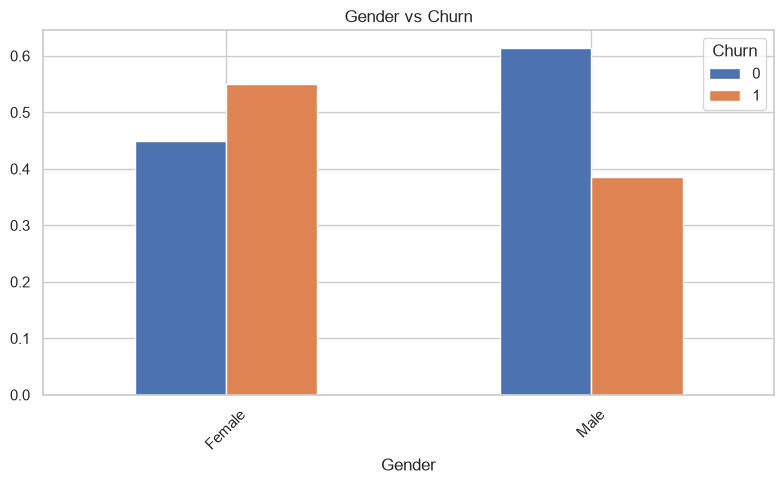

In [26]:
gender_rate = pd.crosstab(df["Gender"], df["Churn"], normalize="index")
display(gender_rate)

fig, ax = plt.subplots(figsize=(8, 5))
gender_rate.plot(kind="bar", ax=ax)
ax.set_title("Gender vs Churn")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


## 29. Subscription Type vs Churn

Churn,0,1
Subscription Type,,
Basic,0.517225,0.482775
Premium,0.535036,0.464964
Standard,0.526695,0.473305


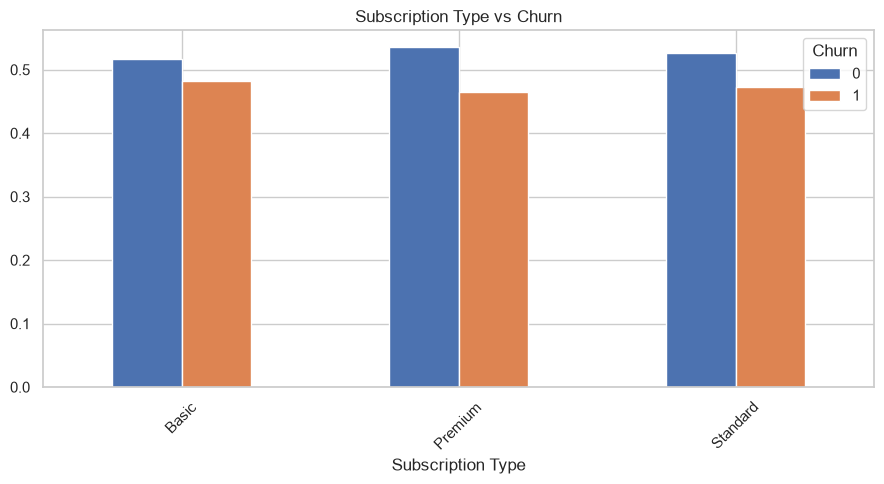

In [27]:
subscription_rate = pd.crosstab(df["Subscription Type"], df["Churn"], normalize="index")
display(subscription_rate)

fig, ax = plt.subplots(figsize=(9, 5))
subscription_rate.plot(kind="bar", ax=ax)
ax.set_title("Subscription Type vs Churn")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


## 30. Contract Length vs Churn

Churn,0,1
Contract Length,,
Annual,0.537833,0.462167
Monthly,0.483913,0.516087
Quarterly,0.559518,0.440482


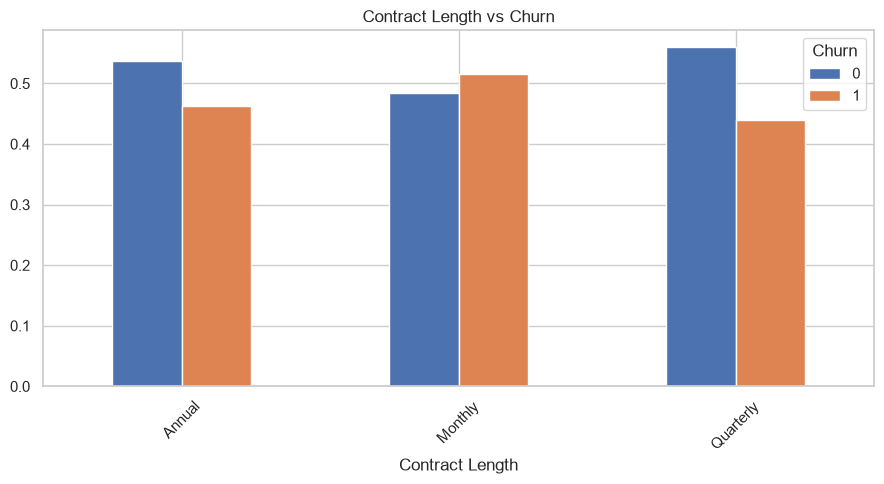

In [28]:
contract_rate = pd.crosstab(df["Contract Length"], df["Churn"], normalize="index")
display(contract_rate)

fig, ax = plt.subplots(figsize=(9, 5))
contract_rate.plot(kind="bar", ax=ax)
ax.set_title("Contract Length vs Churn")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


## 31. Numerical Correlation Heatmap

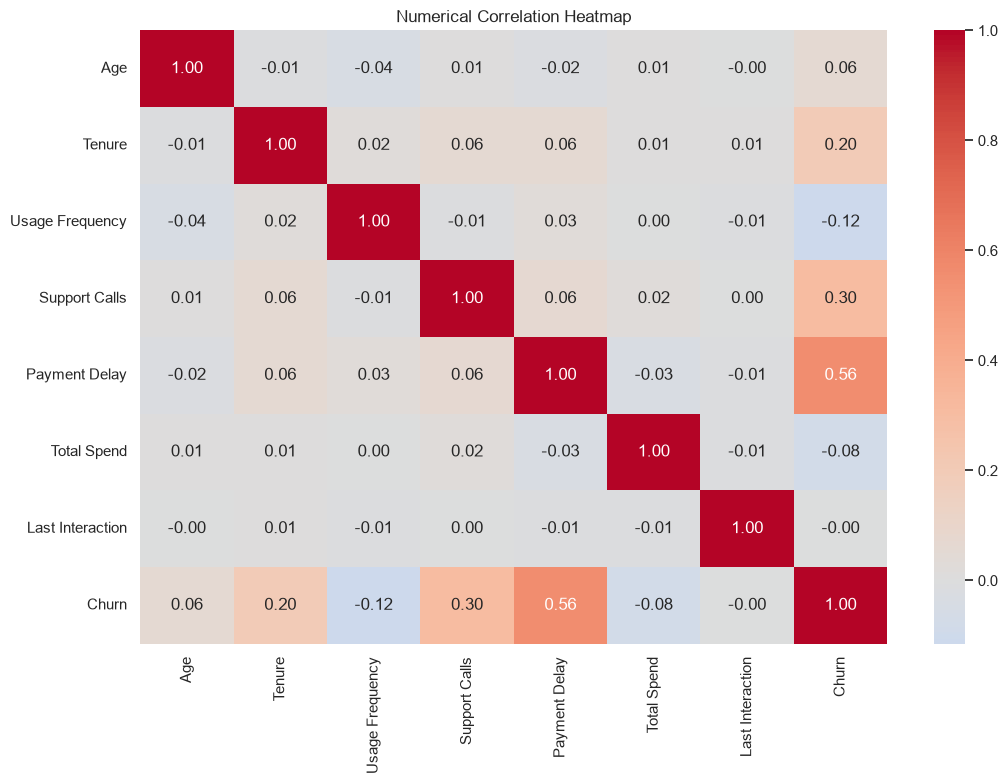

In [29]:
correlation = df[numerical_columns + ["Churn"]].corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Numerical Correlation Heatmap")
plt.tight_layout()
plt.show()


## 32. Correlation Ranking

,Absolute Correlation
Payment Delay,0.557386
Support Calls,0.304631
Tenure,0.195327
Usage Frequency,0.115098
Total Spend,0.078867
Age,0.063457
Last Interaction,0.002818


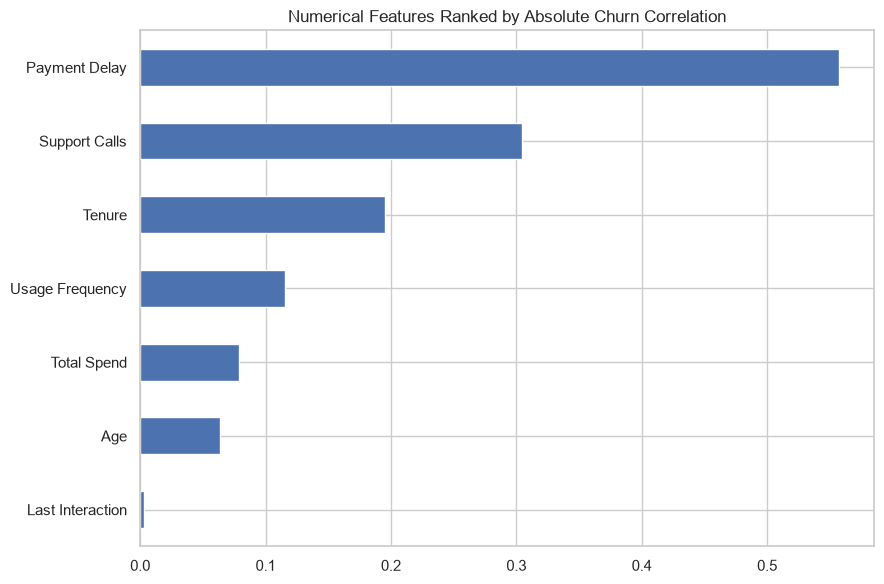

In [30]:
ranking = correlation["Churn"].drop("Churn").abs().sort_values(ascending=False)
display(ranking.to_frame("Absolute Correlation"))

ranking.plot(kind="barh", figsize=(9, 6))
plt.title("Numerical Features Ranked by Absolute Churn Correlation")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


## 33. Target-Pattern Audit

In [31]:
pattern_result = subprocess.run(
    [sys.executable, str(ROOT / "scripts" / "analyze_target_pattern.py")],
    cwd=ROOT,
    check=True,
    capture_output=True,
    text=True,
)
print(pattern_result.stdout)


{
  "holdout_split": "20% validation, random_state=42",
  "no_customer_id_used": true,
  "exact_duplicate_feature_rows": 0,
  "conflicting_duplicate_feature_labels": 0,
  "numeric_target_correlations": {
    "Usage Frequency": -0.11509830085414229,
    "Total Spend": -0.07886737880830706,
    "Last Interaction": -0.002818027024172096,
    "Age": 0.06345696261769648,
    "Tenure": 0.1953272236421314,
    "Support Calls": 0.3046311367131653,
    "CustomerID": 0.5298315536981277,
    "Payment Delay": 0.5573857149857263
  },
  "simple_support_calls_ge5_accuracy": 0.6611054152297512,
  "payment_delay_rule_accuracies": {
    "10": 0.6662472426756144,
    "15": 0.7660390841022773,
    "20": 0.7613943517569205,
    "25": 0.6632336036287942
  },
  "shallow_decision_tree_results": {
    "1": {
      "training_accuracy": 0.7858405017573157,
      "validation_accuracy": 0.7850097087378641
    },
    "2": {
      "training_accuracy": 0.8180353016563429,
      "validation_accuracy": 0.82073786407766

## 34. Interpretation of Target Patterns


Strong relationships between customer behavior fields and `Churn` explain why multiple models perform very well.
The audit also checks:

- Duplicate feature rows.
- Conflicting labels for the same feature combination.
- Whether `CustomerID` is included.
- Whether simple thresholds achieve unusually high accuracy.

Strong feature relationships are not automatically evidence of leakage.
There is no evidence of conflicting duplicate labels or identifier leakage in this pipeline.


## 35. Feature Engineering Decision


`CustomerID` is removed because it is an identifier rather than a customer behavior variable.
No target-derived features are created.
No synthetic rows or oversampling are used.


## 36. Separate Features and Target

In [32]:
X = df.drop(columns=["Churn", "CustomerID"])
y = df["Churn"].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (64374, 10)
y shape: (64374,)


## 37. Reidentify Model Feature Types

In [33]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric:", numeric_features)
print("Categorical:", categorical_features)


Numeric: ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']
Categorical: ['Gender', 'Subscription Type', 'Contract Length']


## 38. Leakage-Safe Preprocessing


The pipeline applies transformations inside cross-validation folds.
Numeric features use median imputation and standard scaling.
Categorical features use most-frequent imputation and one-hot encoding.


## 39. Build the ColumnTransformer

In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])


## 40. Stratified 80:20 Split

In [35]:
from sklearn.model_selection import train_test_split

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Full training rows:", X_train_full.shape[0])
print("Untouched test rows:", X_test.shape[0])


Full training rows:

 51499
Untouched test rows: 12875


## 41. Keep the Test Set Untouched


The test set is not used to select models, tune hyperparameters or choose thresholds.
It is used exactly once for the final evaluation.


## 42. Dummy Baseline

In [36]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy="most_frequent", random_state=42)
baseline.fit(X_train_full, y_train_full)
baseline_prediction = baseline.predict(X_test)

print("Dummy baseline accuracy:", accuracy_score(y_test, baseline_prediction))


Dummy baseline accuracy: 0.5262912621359224


## 43. Execute the Eleven-Model Training Script

In [37]:
train_result = subprocess.run(
    [sys.executable, str(ROOT / "scripts" / "train_models.py")],
    cwd=ROOT,
    check=True,
    capture_output=True,
    text=True,
)
print(train_result.stdout[-14000:])


Training 11 models...
{'Model': 'Logistic Regression', 'Accuracy': 0.8258333333333333, 'Precision': 0.8094540759748702, 'Recall': 0.8270937429275381, 'F1': 0.8181583366349697, 'ROC-AUC': 0.9050901800468806, 'Validation Accuracy': 0.8297087378640776, 'Validation Precision': 0.8128128128128128, 'Validation Recall': 0.8321377331420373, 'Validation F1': 0.8223617581527243, 'Validation ROC-AUC': 0.9058729839878236, 'Training Seconds': 3.13, 'Status': 'Success', 'Error': ''}
{'Model': 'K-Nearest Neighbors', 'Accuracy': 0.8959333333333334, 'Precision': 0.8608518422284357, 'Recall': 0.9307529307331398, 'F1': 0.8944350170801109, 'ROC-AUC': 0.9682346133491057, 'Validation Accuracy': 0.9111650485436893, 'Validation Precision': 0.8782442748091603, 'Validation Recall': 0.9432260709161714, 'Validation F1': 0.9095760450637415, 'Validation ROC-AUC': 0.9766299247167924, 'Training Seconds': 7.71, 'Status': 'Success', 'Error': ''}
{'Model': 'Decision Tree', 'Accuracy': 0.9904999999999999, 'Precision': 0.

## 44. Model Comparison Table

In [38]:
comparison = pd.read_csv(COMPARISON_PATH)
display(comparison)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Validation ROC-AUC,Training Seconds,Status,Error
0,LightGBM,0.999600,0.999507,0.999648,0.999578,0.999997,0.999903,0.999795,1.000000,0.999898,1.000000,2.76,Success,NaN
1,HistGradientBoosting,0.999367,0.999226,0.999437,0.999332,0.999998,0.999806,0.999795,0.999795,0.999795,0.999999,2.65,Success,NaN
2,CatBoost,0.999733,0.999718,0.999718,0.999718,0.999999,0.999709,1.000000,0.999385,0.999692,1.000000,12.11,Success,NaN
3,XGBoost,0.999633,0.999578,0.999648,0.999613,0.999977,0.999709,0.999795,0.999590,0.999693,1.000000,3.45,Success,NaN
4,Random Forest,0.995367,0.998231,0.991977,0.995093,0.999950,0.998252,0.998769,0.997540,0.998154,0.999991,3.27,Success,NaN
5,Decision Tree,0.990500,0.993201,0.986700,0.989938,0.999164,0.992816,0.993225,0.991597,0.992410,0.999775,2.71,Success,NaN
6,Gradient Boosting,0.991933,0.995039,0.987896,0.991454,0.999188,0.992524,0.995869,0.988317,0.992079,0.999134,8.58,Success,NaN
7,Extra Trees,0.958567,0.950406,0.962773,0.956547,0.993757,0.966505,0.955953,0.974175,0.964978,0.996206,3.56,Success,NaN
8,K-Nearest Neighbors,0.895933,0.860852,0.930753,0.894435,0.968235,0.911165,0.878244,0.943226,0.909576,0.976630,7.71,Success,NaN
9,Logistic Regression,0.825833,0.809454,0.827094,0.818158,0.905090,0.829709,0.812813,0.832138,0.822362,0.905873,3.13,Success,NaN


## 45. Cross-Validation Accuracy Comparison

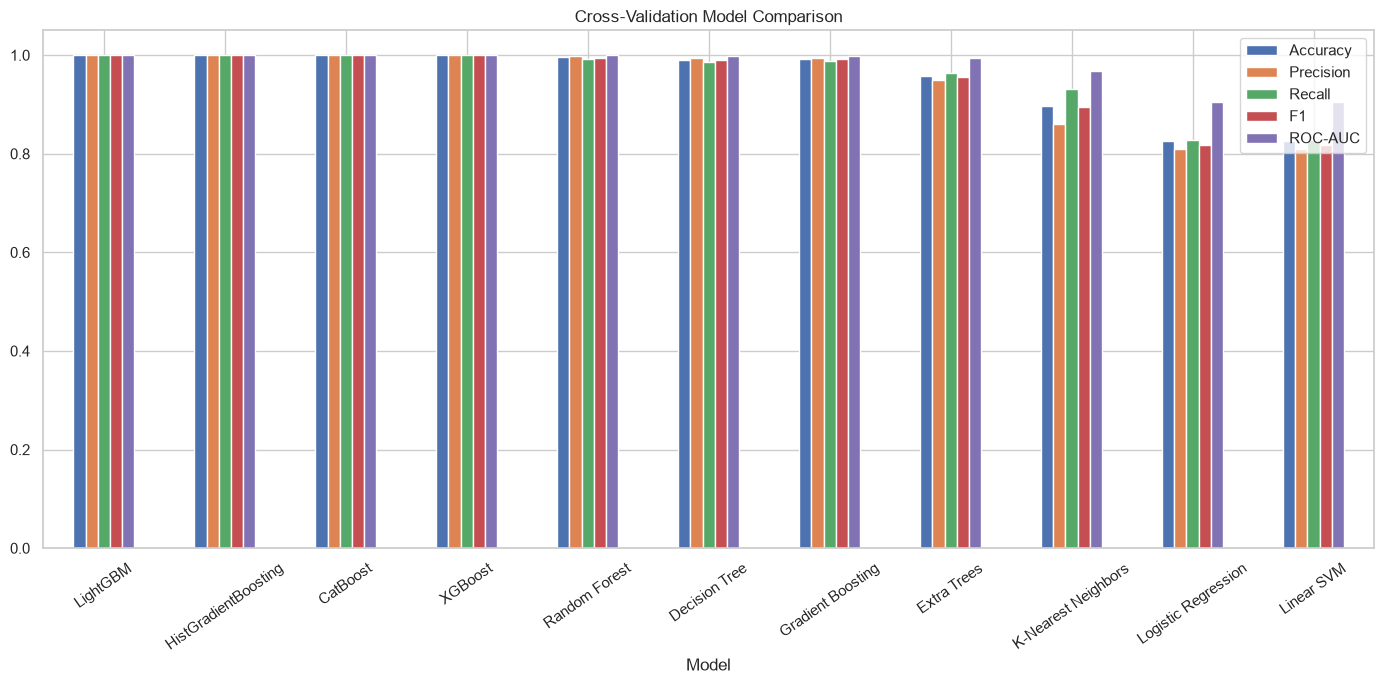

In [39]:
successful = comparison[comparison["Status"] == "Success"].copy()
if not successful.empty:
    successful.set_index("Model")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot(
        kind="bar", figsize=(14, 7)
    )
    plt.title("Cross-Validation Model Comparison")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()


## 46. Validation Accuracy Comparison

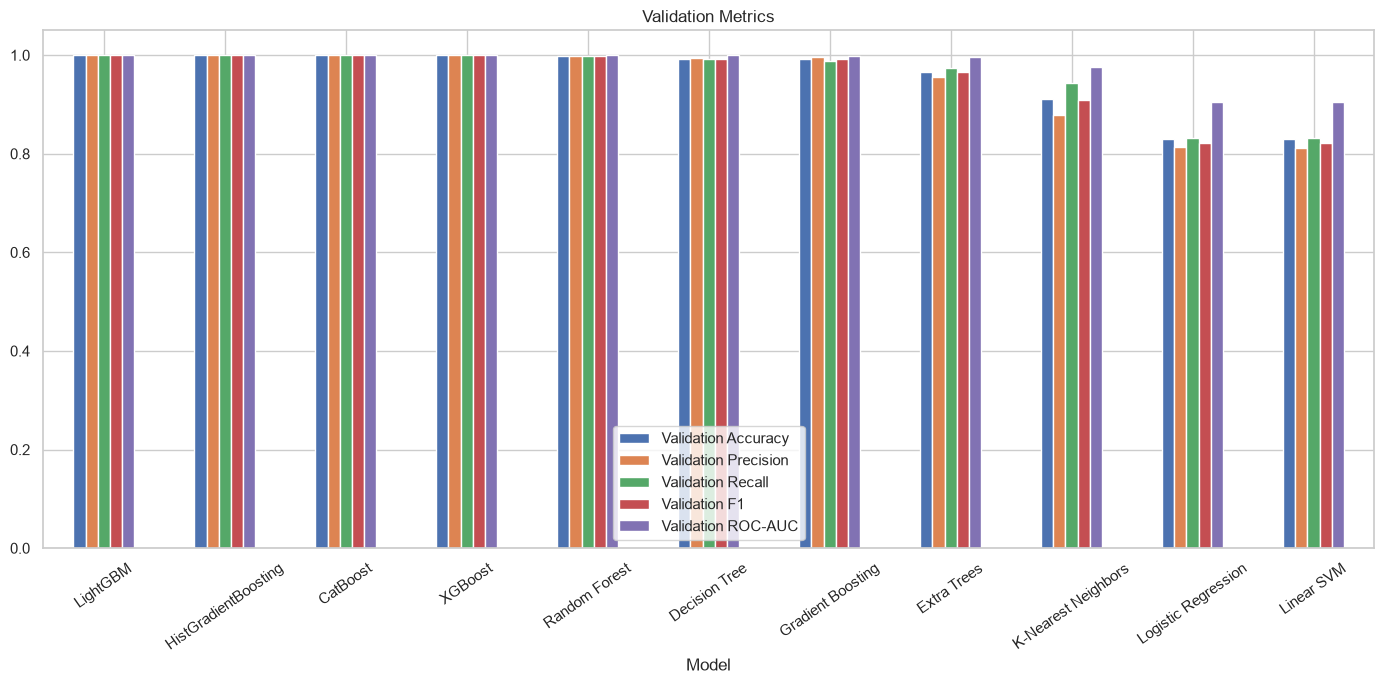

In [40]:
if "Validation Accuracy" in successful.columns:
    successful.sort_values("Validation Accuracy", ascending=False).set_index("Model")[
        ["Validation Accuracy", "Validation Precision", "Validation Recall",
         "Validation F1", "Validation ROC-AUC"]
    ].plot(kind="bar", figsize=(14, 7))
    plt.title("Validation Metrics")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()


## 47. Training-Time Comparison

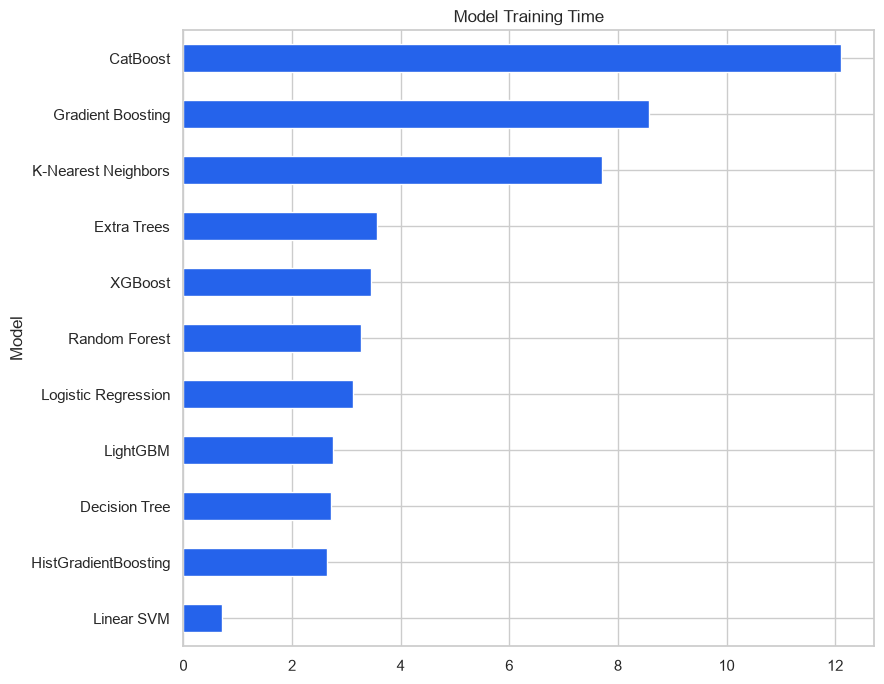

In [41]:
if "Training Seconds" in successful.columns:
    successful.sort_values("Training Seconds").set_index("Model")["Training Seconds"].plot(
        kind="barh", figsize=(9, 7), color="#2563eb"
    )
    plt.title("Model Training Time")
    plt.tight_layout()
    plt.show()


## 48. Load Final Metrics

In [42]:
metrics = json.loads(METRICS_PATH.read_text(encoding="utf-8"))
print("Selected model:", metrics["selected_model"])
print("OOF threshold:", metrics["threshold_selection"]["threshold"])
print("Baseline:", metrics["baseline"])
print("Final test:", metrics["final_test"])


Selected model: LightGBM
OOF threshold: 0.34500000000000003
Baseline: {'accuracy': 0.5262912621359224, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'roc_auc': 0.5}
Final test: {'accuracy': 0.9998446601941747, 'precision': 0.9996721848877234, 'recall': 1.0, 'f1': 0.9998360655737705, 'roc_auc': 1.0}


## 49. Cross-Validation vs Validation vs Test


These metrics measure different stages:

- **Cross-validation:** folds inside the 30,000-row subset.
- **Validation:** 20% holdout inside the 80% training split.
- **Out-of-fold threshold:** 5-fold probabilities on the full 80% training split.
- **Test:** 12,875 rows evaluated once after model and threshold selection.


## 50. Hyperparameter Tuning

In [43]:
display(metrics["hyperparameter_tuning"])


{'best_params': {'model__learning_rate': 0.1, 'model__num_leaves': 31},
 'best_validation_accuracy': 0.9995630961916552}

## 51. OOF Threshold Method

In [44]:
display(metrics["threshold_selection"])


{'method': '5-fold out-of-fold predictions on 80% training split',
 'metric': 'accuracy',
 'threshold': 0.34500000000000003,
 'frozen_before_test_evaluation': True}

## 52. Load the Saved Pipeline

In [45]:
model = joblib.load(MODEL_PATH)
print("Model type:", type(model).__name__)
print("Fitted pipeline steps:", list(model.named_steps))


Model type: Pipeline
Fitted pipeline steps: ['preprocessing', 'model']


## 53. Verify CustomerID Is Not a Model Input

In [46]:
preprocessor = model.named_steps["preprocessing"]
feature_names = model.feature_names_in_.tolist()
print("CustomerID in pipeline inputs:", "CustomerID" in feature_names)
print("Model input count:", len(feature_names))
print("First model inputs:", feature_names[:15])


CustomerID in pipeline inputs: False
Model input count: 10
First model inputs: ['Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend', 'Last Interaction']


## 54. Feature Importance

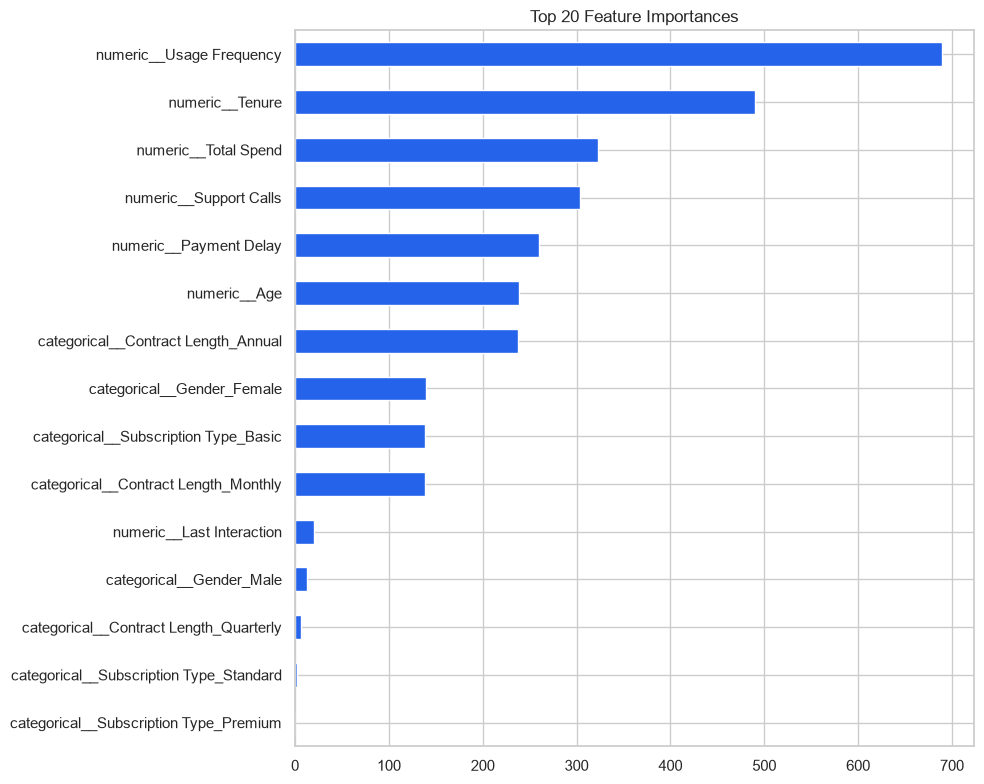

In [47]:
estimator = model.named_steps["model"]
if hasattr(estimator, "feature_importances_"):
    names = preprocessor.get_feature_names_out()
    importance = pd.Series(estimator.feature_importances_, index=names)
    importance = importance.sort_values(ascending=False).head(20)
    importance.iloc[::-1].plot(kind="barh", figsize=(10, 8), color="#2563eb")
    plt.title("Top 20 Feature Importances")
    plt.tight_layout()
    plt.show()
else:
    print("The selected model does not expose native feature importances.")


## 55. Final Test Predictions

In [48]:
probability = model.predict_proba(X_test)[:, 1]
threshold = metrics["threshold_selection"]["threshold"]
prediction = (probability >= threshold).astype(int)

print("Prediction threshold:", threshold)
print("Predicted churn count:", int(prediction.sum()))
print("Predicted stay count:", int((1 - prediction).sum()))


Prediction threshold: 0.34500000000000003
Predicted churn count: 6101
Predicted stay count: 6774


## 56. Confusion Matrix

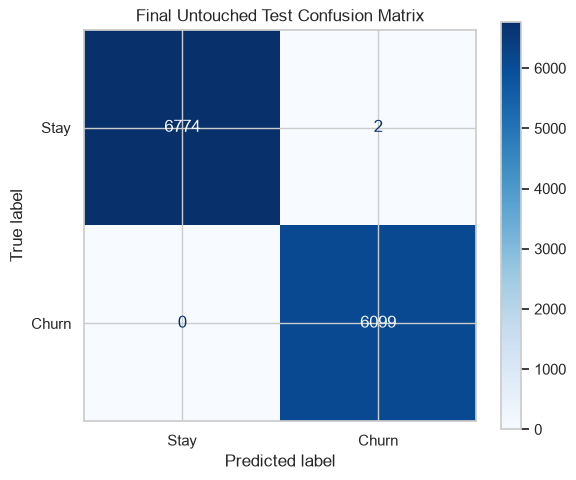

In [49]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    prediction,
    display_labels=["Stay", "Churn"],
    cmap="Blues",
    ax=ax,
)
ax.set_title("Final Untouched Test Confusion Matrix")
plt.tight_layout()
plt.show()


## 57. Classification Report

In [50]:
print(classification_report(y_test, prediction, target_names=["Stay", "Churn"], digits=4))


              precision    recall  f1-score   support

        Stay     1.0000    0.9997    0.9999      6776
       Churn     0.9997    1.0000    0.9998      6099

    accuracy                         0.9998     12875
   macro avg     0.9998    0.9999    0.9998     12875
weighted avg     0.9998    0.9998    0.9998     12875



## 58. ROC Curve

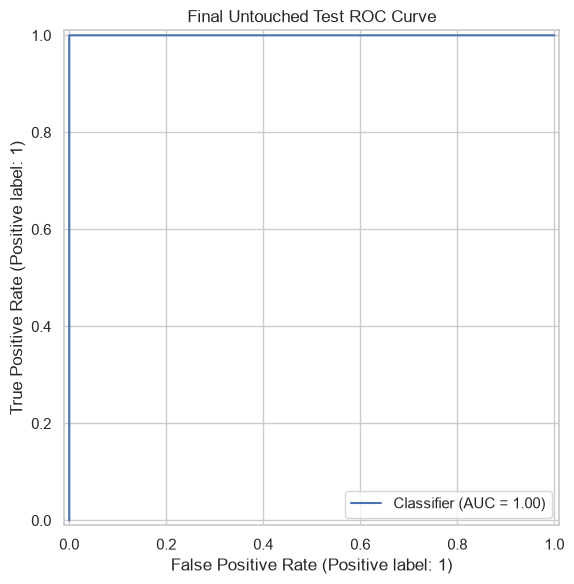

In [51]:
fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(y_test, probability, ax=ax)
ax.set_title("Final Untouched Test ROC Curve")
plt.tight_layout()
plt.show()


## 59. Precision-Recall Curve

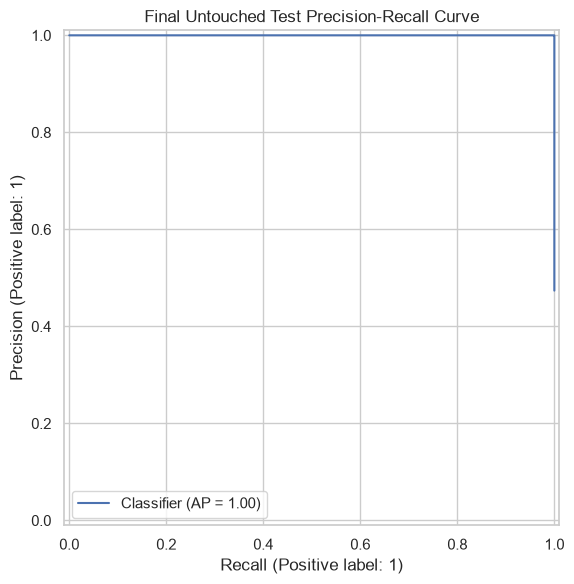

In [52]:
fig, ax = plt.subplots(figsize=(7, 6))
PrecisionRecallDisplay.from_predictions(y_test, probability, ax=ax)
ax.set_title("Final Untouched Test Precision-Recall Curve")
plt.tight_layout()
plt.show()


## 60. Actual vs Predicted Distribution

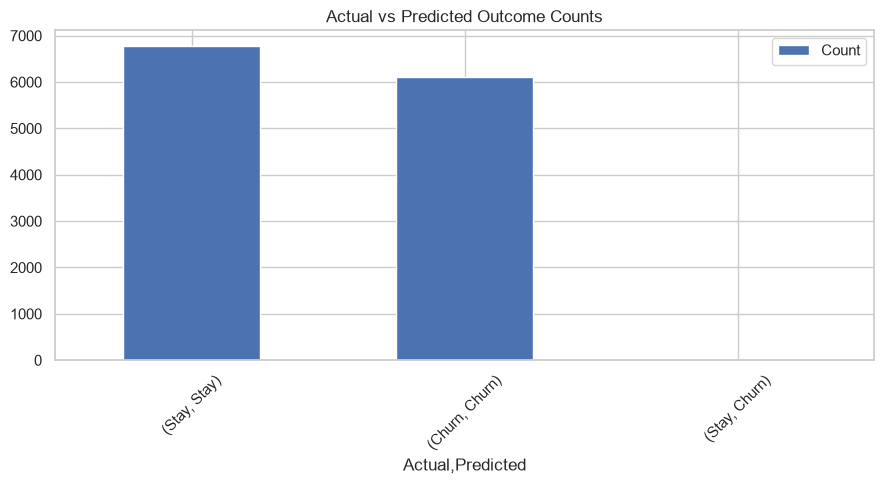

In [53]:
pd.DataFrame({
    "Actual": y_test.map({0: "Stay", 1: "Churn"}),
    "Predicted": pd.Series(prediction).map({0: "Stay", 1: "Churn"}).values,
}).value_counts().rename("Count").to_frame().plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Actual vs Predicted Outcome Counts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 61. False Positives and False Negatives


- False positive: predicted churn, but the customer stayed.
- False negative: predicted stay, but the customer churned.

For retention, false negatives are usually important because missed churners do not receive intervention.


## 62. Limitations


Near-perfect performance must be interpreted cautiously.
This audit found strong rule-like relationships in the target structure, but no direct proof of target leakage.
Strong synthetic patterns can produce very high accuracy even though the feature values are ordinary account measurements.


## 63. Final Model Metrics

In [54]:
final = metrics["final_test"]
print("Selected model:", metrics["selected_model"])
print("Accuracy:", f"{final['accuracy']:.6%}")
print("Precision:", f"{final['precision']:.6%}")
print("Recall:", f"{final['recall']:.6%}")
print("F1:", f"{final['f1']:.6f}")
print("ROC-AUC:", f"{final['roc_auc']:.6f}")
print("90% target achieved:", metrics["target_90_percent_achieved"])


Selected model: LightGBM
Accuracy: 99.984466%
Precision: 99.967218%
Recall: 100.000000%
F1: 0.999836
ROC-AUC: 1.000000
90% target achieved: True


## 64. Smoke Test the Reloaded Model

In [55]:
smoke_predictions = model.predict(X_test.iloc[:20])
print("Reloaded model test predictions:", smoke_predictions.tolist())


Reloaded model test predictions: [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1]


## 65. Conclusion


The final selected pipeline is LightGBM with an out-of-fold-selected threshold.
The untouched test set reported near-perfect accuracy.

The model result should be reported honestly with:

- Exact test metrics.
- Confusion matrix.
- Target-pattern findings.
- Dummy-baseline comparison.
- The possibility of strong synthetic or rule-like structure.

This is the complete end-to-end analysis; deployment decisions should not rely on accuracy alone.


## Dataset Ordering and Split Overlap Audit

CustomerID is excluded from model inputs. The source file nevertheless has a marked churn-rate shift across CustomerID deciles, which may reflect source ordering or target-generation structure. This warrants caution when interpreting random-split test performance; the dataset does not document the label-generation process.

In [56]:
import json
from pathlib import Path
metrics = json.loads((Path.cwd() / "model_metrics.json").read_text(encoding="utf-8"))
print("CustomerID excluded:", metrics["leakage_audit"]["customer_id_excluded_from_features"])
print("CustomerID/churn correlation (descriptive):", round(metrics["leakage_audit"]["customer_id_churn_correlation_descriptive_only"], 3))
print("Churn rate by CustomerID decile:", metrics["leakage_audit"]["churn_rate_by_customer_id_decile"])
print("Train/test ID overlap:", metrics["leakage_audit"]["train_test_customer_id_overlap"])
print("Train/test feature-row overlap:", metrics["leakage_audit"]["train_test_feature_row_overlap"])
print("Interpretation:", metrics["leakage_audit"]["interpretation"])

CustomerID excluded: True
CustomerID/churn correlation (descriptive): 0.53
Churn rate by CustomerID decile: {'0': 0.2590866728797763, '1': 0.26549634923100823, '2': 0.2527574957278235, '3': 0.2527182354768562, '4': 0.2605250893273264, '5': 0.2581948112474755, '6': 0.2589313451382417, '7': 0.9291595463725338, '8': 1.0, '9': 1.0}
Train/test ID overlap: 0
Train/test feature-row overlap: 0
Interpretation: CustomerID is excluded, but churn is highly ordered by CustomerID; high-ID deciles are nearly all churn. This suggests target ordering or source generation structure and limits random-split generalization claims. The source data does not establish the target-generation process.
